In [1]:
!pip install --upgrade keras tensorflow

import keras

try:
    model = keras.saving.load_model('/content/cnn_selected_for_xai.keras')
    model.summary()
except Exception as e:
    print("Error loading model:", e)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,264,928 (4.83 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 843,286 (3.22 MB)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Test images shape: (10000, 28, 28, 1)
Test labels shape: (10000,)


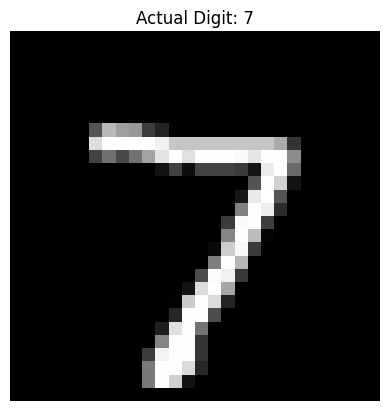

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Load MNIST test dataset
(_, _), (x_test, y_test) = mnist.load_data()

# Normalize images and add channel dimension
x_test = x_test.astype("float32") / 255.0
x_test = np.expand_dims(x_test, axis=-1)

print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

# Display a sample image
plt.imshow(x_test[0].squeeze(), cmap="gray")
plt.title(f"Actual Digit: {y_test[0]}")
plt.axis("off")
plt.show()


In [3]:

import numpy as np

# Select the first MNIST test image
image = x_test[0:1]

# Get CNN prediction
prediction = model.predict(image, verbose=0)

predicted_digit = np.argmax(prediction[0])
confidence = np.max(prediction[0]) * 100

print("Actual Digit:", y_test[0])
print("Predicted Digit:", predicted_digit)
print(f"Confidence: {confidence:.2f}%")


Actual Digit: 7
Predicted Digit: 7
Confidence: 100.00%


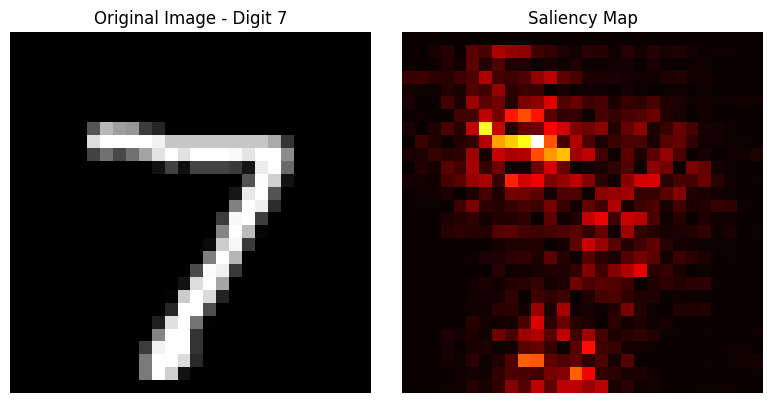

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Select the first MNIST test image
input_image = tf.convert_to_tensor(x_test[0:1])

# Calculate gradients for the predicted digit
with tf.GradientTape() as tape:
    tape.watch(input_image)
    predictions = model(input_image, training=False)
    predicted_class = tf.argmax(predictions[0])
    class_score = predictions[0, predicted_class]

gradients = tape.gradient(class_score, input_image)

# Generate saliency map
saliency = tf.abs(gradients)
saliency = tf.reduce_max(saliency, axis=-1)[0]
saliency = saliency.numpy()

# Normalize saliency values for visualization
saliency = saliency / (np.max(saliency) + 1e-8)

# Display original image and saliency map
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(x_test[0].squeeze(), cmap="gray")
plt.title("Original Image - Digit 7")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(saliency, cmap="hot")
plt.title("Saliency Map")
plt.axis("off")

plt.tight_layout()
plt.show()


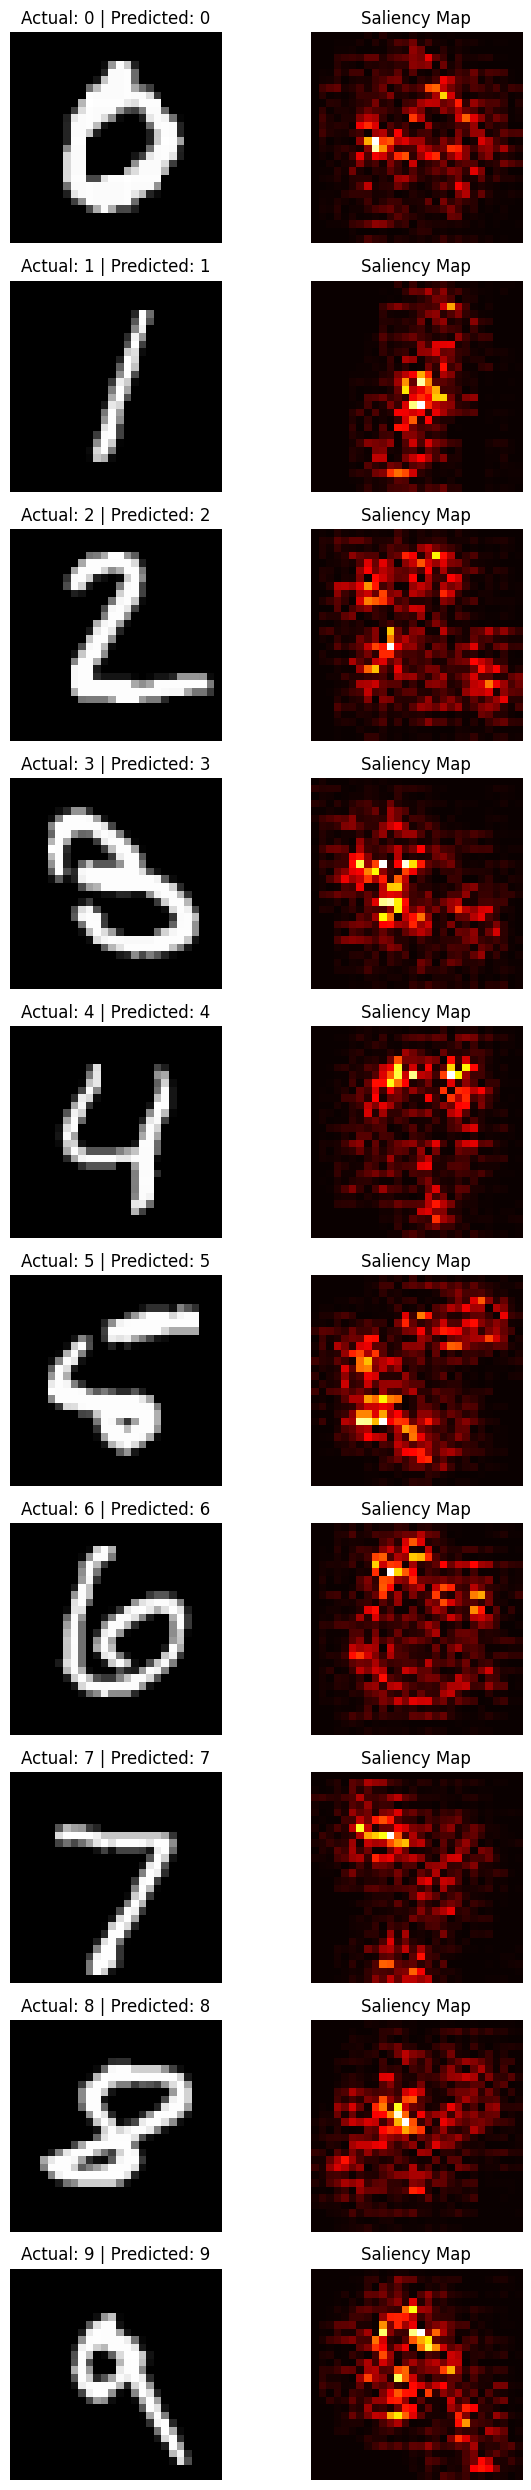

In [5]:

# Generate saliency maps for digits 0 to 9

fig, axes = plt.subplots(10, 2, figsize=(7, 25))

for digit in range(10):
    # Find an MNIST test image for this digit
    idx = np.where(y_test == digit)[0][0]
    input_image = tf.convert_to_tensor(x_test[idx:idx+1])

    with tf.GradientTape() as tape:
        tape.watch(input_image)
        predictions = model(input_image, training=False)
        predicted_class = tf.argmax(predictions[0])
        score = predictions[0, predicted_class]

    gradients = tape.gradient(score, input_image)

    saliency = tf.reduce_max(
        tf.abs(gradients), axis=-1
    )[0].numpy()

    saliency /= (np.max(saliency) + 1e-8)

    predicted_digit = int(predicted_class.numpy())

    axes[digit, 0].imshow(
        x_test[idx].squeeze(), cmap="gray"
    )
    axes[digit, 0].set_title(
        f"Actual: {digit} | Predicted: {predicted_digit}"
    )
    axes[digit, 0].axis("off")

    axes[digit, 1].imshow(saliency, cmap="hot")
    axes[digit, 1].set_title("Saliency Map")
    axes[digit, 1].axis("off")

plt.tight_layout()
plt.savefig("saliency_maps_all_digits.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [6]:

# Inspect the model before implementing Grad-CAM
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

for layer in model.layers:
    print(layer.name, layer.__class__.__name__, layer.output.shape)


Model input shape: (None, 28, 28, 1)
Model output shape: (None, 10)
conv2d Conv2D (None, 28, 28, 32)
max_pooling2d MaxPooling2D (None, 14, 14, 32)
conv2d_1 Conv2D (None, 14, 14, 64)
max_pooling2d_1 MaxPooling2D (None, 7, 7, 64)
flatten Flatten (None, 3136)
dense Dense (None, 128)
dropout Dropout (None, 128)
dense_1 Dense (None, 10)


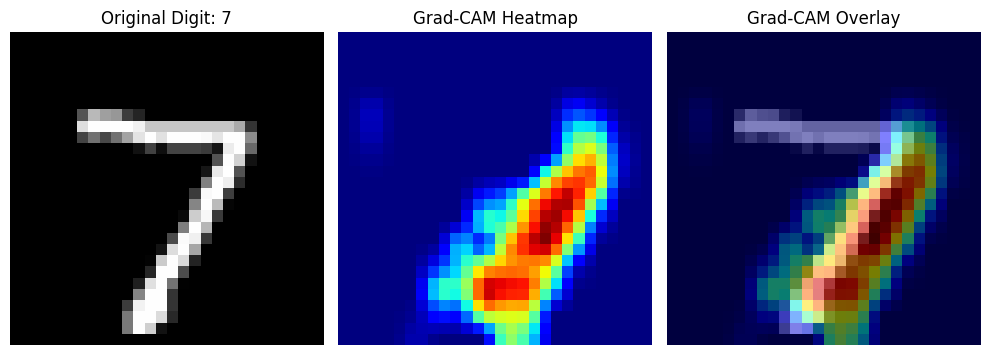

In [7]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Rebuild a connected model for Grad-CAM
inputs = tf.keras.Input(shape=(28, 28, 1))
x = inputs
conv_output = None

for layer in model.layers:
    x = layer(x)
    if layer.name == "conv2d_1":
        conv_output = x

grad_model = tf.keras.Model(
    inputs=inputs,
    outputs=[conv_output, x]
)

# Select first MNIST test image
input_image = tf.convert_to_tensor(x_test[0:1])

with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(
        input_image, training=False
    )
    predicted_class = tf.argmax(predictions[0])
    class_score = predictions[0, predicted_class]

# Calculate gradients
grads = tape.gradient(class_score, conv_outputs)

# Average gradients across spatial dimensions
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

# Weight feature maps by their gradients
heatmap = tf.reduce_sum(
    conv_outputs[0] * pooled_grads, axis=-1
)

# Keep positive contributions
heatmap = tf.maximum(heatmap, 0)

# Normalize heatmap
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = heatmap.numpy()

# Resize heatmap to original image size
heatmap = tf.image.resize(
    heatmap[..., np.newaxis], (28, 28)
).numpy().squeeze()

# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(x_test[0].squeeze(), cmap="gray")
plt.title("Original Digit: 7")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(x_test[0].squeeze(), cmap="gray")
plt.imshow(heatmap, cmap="jet", alpha=0.5)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.savefig("gradcam_digit7.png", dpi=300,
            bbox_inches="tight")
plt.show()


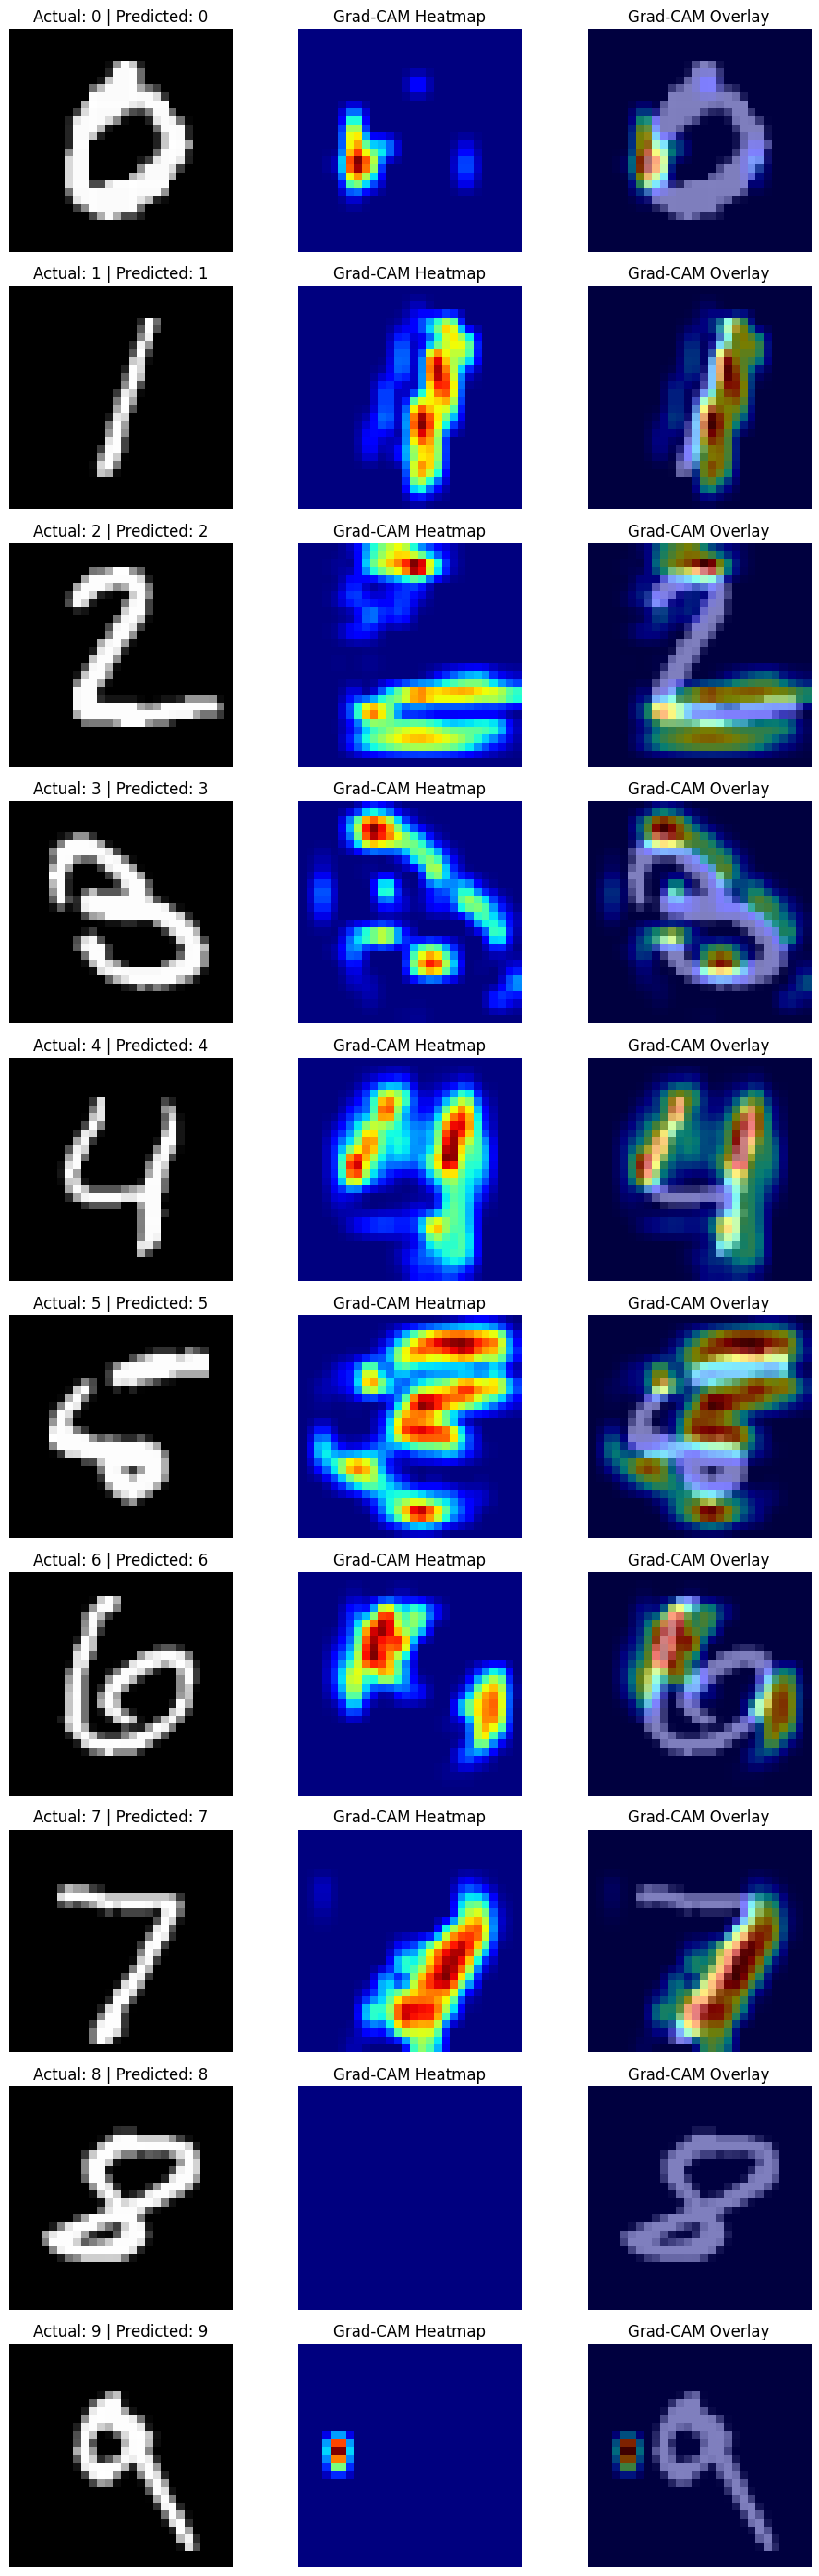

In [8]:

fig, axes = plt.subplots(10, 3, figsize=(10, 28))

for digit in range(10):
    idx = np.where(y_test == digit)[0][0]
    input_image = tf.convert_to_tensor(x_test[idx:idx+1])

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            input_image, training=False
        )
        predicted_class = tf.argmax(predictions[0])
        score = predictions[0, predicted_class]

    grads = tape.gradient(score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    heatmap = tf.reduce_sum(
        conv_outputs[0] * pooled_grads, axis=-1
    )
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    heatmap = tf.image.resize(
        heatmap[..., np.newaxis], (28, 28)
    ).numpy().squeeze()

    predicted_digit = int(predicted_class.numpy())

    axes[digit, 0].imshow(x_test[idx].squeeze(), cmap="gray")
    axes[digit, 0].set_title(
        f"Actual: {digit} | Predicted: {predicted_digit}"
    )
    axes[digit, 0].axis("off")

    axes[digit, 1].imshow(heatmap, cmap="jet")
    axes[digit, 1].set_title("Grad-CAM Heatmap")
    axes[digit, 1].axis("off")

    axes[digit, 2].imshow(x_test[idx].squeeze(), cmap="gray")
    axes[digit, 2].imshow(heatmap, cmap="jet", alpha=0.5)
    axes[digit, 2].set_title("Grad-CAM Overlay")
    axes[digit, 2].axis("off")

plt.tight_layout()
plt.savefig("gradcam_all_digits.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [9]:

!pip install lime


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 1.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=fd9e91fffb34f8c714510c66074546d803c83a63fcdbe2a7c4f776e8d515a845
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


  0%|          | 0/1000 [00:00<?, ?it/s]

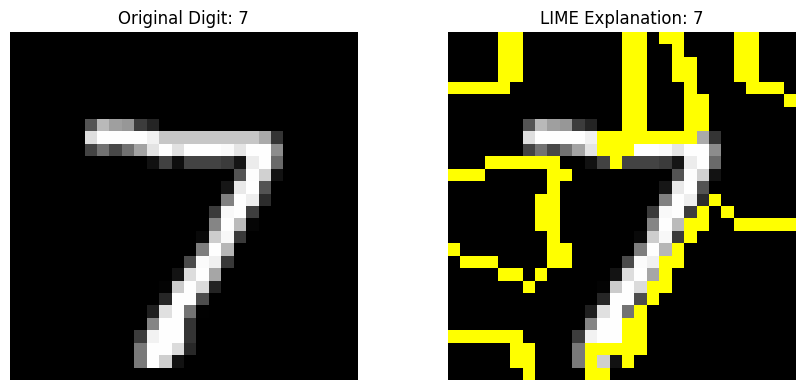

In [10]:

import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries, slic

# Function to prepare LIME images for the CNN
def predict_fn(images):
    images = np.asarray(images, dtype=np.float32)

    # Convert RGB images to grayscale
    if images.ndim == 4 and images.shape[-1] == 3:
        images = np.mean(images, axis=-1)

    # Restore the channel dimension
    if images.ndim == 3:
        images = images[..., np.newaxis]

    return model.predict(images, verbose=0)

# Select the first MNIST test image (digit 7)
idx = 0
original_image = x_test[idx].squeeze()

# Convert grayscale to RGB for LIME
rgb_image = np.repeat(
    original_image[..., np.newaxis], 3, axis=-1
)

# Create image regions for LIME
def segment_fn(image):
    return slic(
        image,
        n_segments=30,
        compactness=0.1,
        sigma=0,
        start_label=0,
        channel_axis=-1
    )

# Initialise LIME
explainer = lime_image.LimeImageExplainer(random_state=42)

# Generate explanation
explanation = explainer.explain_instance(
    rgb_image,
    classifier_fn=predict_fn,
    top_labels=1,
    hide_color=0,
    num_samples=1000,
    segmentation_fn=segment_fn
)

# Get the CNN's predicted digit
predicted_digit = int(
    np.argmax(predict_fn(rgb_image[np.newaxis, ...])[0])
)

# Highlight influential image regions
lime_image_result, mask = explanation.get_image_and_mask(
    label=predicted_digit,
    positive_only=True,
    num_features=10,
    hide_rest=False
)

# Display original and LIME explanation
plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap="gray")
plt.title(f"Original Digit: {y_test[idx]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(lime_image_result, mask))
plt.title(f"LIME Explanation: {predicted_digit}")
plt.axis("off")

plt.tight_layout()
plt.savefig("lime_digit7.png", dpi=300,
            bbox_inches="tight")
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

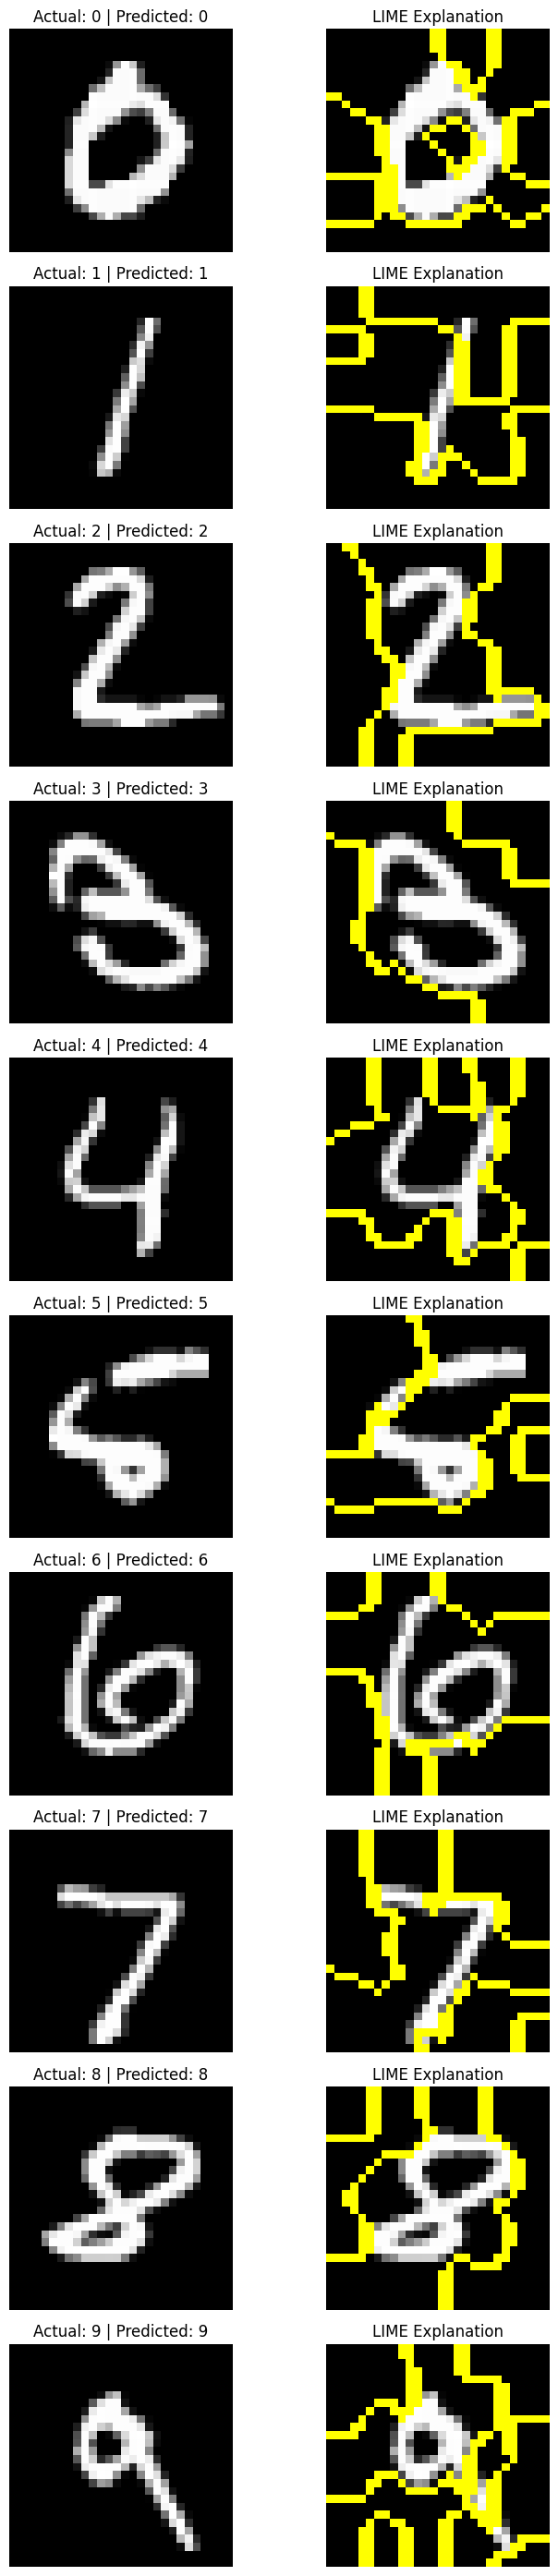

In [11]:

fig, axes = plt.subplots(10, 2, figsize=(8, 28))

for digit in range(10):
    idx = np.where(y_test == digit)[0][0]
    original_image = x_test[idx].squeeze()

    rgb_image = np.repeat(
        original_image[..., np.newaxis], 3, axis=-1
    )

    explanation = explainer.explain_instance(
        rgb_image,
        classifier_fn=predict_fn,
        top_labels=1,
        hide_color=0,
        num_samples=1000,
        segmentation_fn=segment_fn
    )

    predicted_digit = int(
        np.argmax(predict_fn(rgb_image[np.newaxis, ...])[0])
    )

    lime_result, mask = explanation.get_image_and_mask(
        label=predicted_digit,
        positive_only=True,
        num_features=10,
        hide_rest=False
    )

    axes[digit, 0].imshow(original_image, cmap="gray")
    axes[digit, 0].set_title(
        f"Actual: {digit} | Predicted: {predicted_digit}"
    )
    axes[digit, 0].axis("off")

    axes[digit, 1].imshow(
        mark_boundaries(lime_result, mask)
    )
    axes[digit, 1].set_title("LIME Explanation")
    axes[digit, 1].axis("off")

plt.tight_layout()
plt.savefig(
    "lime_all_digits.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

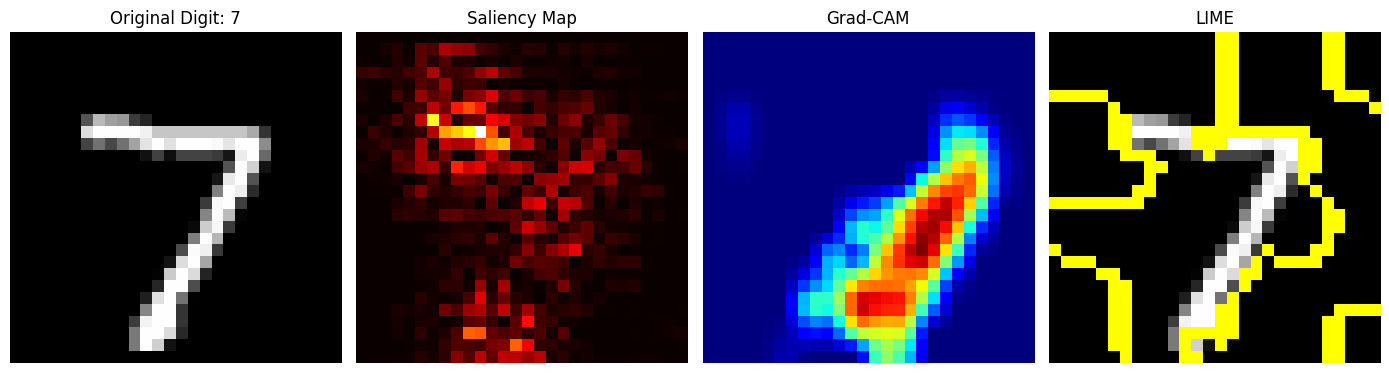

In [13]:

# Correct XAI comparison for digit 7
idx = 0
input_image = tf.convert_to_tensor(x_test[idx:idx+1])

# 1. Saliency map for digit 7
with tf.GradientTape() as tape:
    tape.watch(input_image)
    predictions = model(input_image, training=False)
    predicted_class = tf.argmax(predictions[0])
    score = predictions[0, predicted_class]

grads = tape.gradient(score, input_image)
saliency_7 = tf.reduce_max(tf.abs(grads), axis=-1)[0].numpy()
saliency_7 /= np.max(saliency_7) + 1e-8

# 2. Grad-CAM for digit 7
with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(
        input_image, training=False
    )
    predicted_class = tf.argmax(predictions[0])
    score = predictions[0, predicted_class]

grads = tape.gradient(score, conv_outputs)
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

heatmap_7 = tf.reduce_sum(
    conv_outputs[0] * pooled_grads, axis=-1
)
heatmap_7 = tf.maximum(heatmap_7, 0)
heatmap_7 /= tf.reduce_max(heatmap_7) + 1e-8

heatmap_7 = tf.image.resize(
    heatmap_7[..., np.newaxis], (28, 28)
).numpy().squeeze()

# 3. LIME for digit 7
rgb_image_7 = np.repeat(
    x_test[idx], 3, axis=-1
)

explanation_7 = explainer.explain_instance(
    rgb_image_7,
    classifier_fn=predict_fn,
    top_labels=1,
    hide_color=0,
    num_samples=1000,
    segmentation_fn=segment_fn
)

predicted_digit_7 = int(
    np.argmax(model.predict(x_test[idx:idx+1], verbose=0))
)

lime_result_7, mask_7 = explanation_7.get_image_and_mask(
    label=predicted_digit_7,
    positive_only=True,
    num_features=10,
    hide_rest=False
)

# 4. Compare all three methods
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(x_test[idx].squeeze(), cmap="gray")
axes[0].set_title("Original Digit: 7")

axes[1].imshow(saliency_7, cmap="hot")
axes[1].set_title("Saliency Map")

axes[2].imshow(heatmap_7, cmap="jet")
axes[2].set_title("Grad-CAM")

axes[3].imshow(mark_boundaries(lime_result_7, mask_7))
axes[3].set_title("LIME")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig("xai_comparison_digit7.png",
            dpi=300, bbox_inches="tight")
plt.show()


### Explainable AI Results and Interpretation

Three Explainable AI techniques were used- Saliency Maps, Grad-CAM, and LIME to the trained CNN to evaluate how it classified handwritten digits from the MNIST dataset.

**Saliency Maps:** The visualisations highlighted pixels where changes could strongly affect the predicted class score. For digit 7, most responses appeared around the upper stroke, although some sensitivity was also visible outside the digit.

**Grad-CAM:** The heatmaps identified common regions in the CNN's convolutional feature representations. For digit 7, the strongest responses were concentrated around the diagonal stroke, providing a relatively clear visual explanation.

**LIME:** The method divided the image into segments and focused how concerning those segments affected the prediction. Some positively contributing segments included background regions, suggesting limitations in the segmentation-based explanation for small grayscale images.

**Comparison:** Grad-CAM produced the most visually logical explanation for the selected digit 7, while saliency maps provided finer pixel-level information. LIME offered a model-agnostic perspective but produced more fragmented explanations. These observations are qualitative and do not bais which technique is most faithful to the CNN overall.